In [1]:
# EV Battery Component Detection - RT-DETR Benchmark Notebook

!pip install pandas

import os, time, yaml, random, logging, platform
from pathlib import Path
import numpy as np
import torch
import pandas as pd
from ultralytics import RTDETR
from ultralytics.utils import SETTINGS

SETTINGS.reset()

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("EV-Battery-RTDETR")

print("Ultralytics:", __import__("ultralytics").__version__)
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| Platform:", platform.platform())


Ultralytics: 8.4.6
PyTorch: 1.12.1+cu113 | CUDA: True | Platform: Linux-6.8.0-90-generic-x86_64-with-glibc2.39


In [2]:
# REPRODUCIBILITY

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


# GPU SELECTION 
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
DEVICE = "0" if torch.cuda.is_available() else "cpu"  
logger.info(f"CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']} | device={DEVICE}")

2026-01-26 03:42:43,815 | INFO | CUDA_VISIBLE_DEVICES=2 | device=0


In [3]:
# DATASET PATHS 
ROOT = "/home/240388203/ev-disassembly"
DATA_DIR = f"{ROOT}/datasets/ev_battery_1045"
DATA_YAML = f"{DATA_DIR}/data.yaml"

assert Path(DATA_DIR).exists(), f"Missing DATA_DIR: {DATA_DIR}"
assert Path(DATA_YAML).exists(), f"Missing data.yaml: {DATA_YAML}"

with open(DATA_YAML, "r") as f:
    cfg = yaml.safe_load(f)

# Roboflow sometimes uses valid: not val:
p = Path(DATA_YAML)
txt = p.read_text()
if "\nvalid:" in txt and "\nval:" not in txt:
    p.write_text(txt.replace("\nvalid:", "\nval:"))
    logger.info("Patched YAML: valid -> val")

with open(DATA_YAML, "r") as f:
    cfg = yaml.safe_load(f)

logger.info("Dataset YAML loaded.")
logger.info(f"train: {cfg.get('train')}")
logger.info(f"val:   {cfg.get('val', cfg.get('valid'))}")
logger.info(f"test:  {cfg.get('test')}")
logger.info(f"nc:    {cfg.get('nc')}")
logger.info(f"names: {cfg.get('names')}")


2026-01-26 03:42:43,838 | INFO | Dataset YAML loaded.
2026-01-26 03:42:43,840 | INFO | train: ../train/images
2026-01-26 03:42:43,841 | INFO | val:   ../valid/images
2026-01-26 03:42:43,842 | INFO | test:  ../test/images
2026-01-26 03:42:43,843 | INFO | nc:    8
2026-01-26 03:42:43,844 | INFO | names: ['BMS_Unit', 'Busbars', 'Coolant_tubes', 'battery_module', 'battery_tray', 'fasteners', 'low_volt_cable', 'pack_cover']


In [4]:

# 4) TRAINING CONFIG (RT-DETR)


IMGSZ = 768          
BATCH = 8            
WORKERS = 8

EPOCHS = 50
PATIENCE = 18

PROJECT_DIR = f"{ROOT}/runs_rtdetr"
os.makedirs(PROJECT_DIR, exist_ok=True)

run_name = f"rtdetr_l_1045_{int(time.time())}"  

In [5]:
# TRAIN RT-DETR
logger.info("\n TRAIN RT-DETR ")

model = RTDETR("rtdetr-l.pt")

results = model.train(
    data=DATA_YAML,
    imgsz=IMGSZ,
    epochs=EPOCHS,
    patience=PATIENCE,
    batch=BATCH,
    workers=WORKERS,
    device=DEVICE,
    optimizer="AdamW",
    lr0=1e-4,       
    weight_decay=1e-4,
    warmup_epochs=3,
    cache=False,
    seed=42,
    project=PROJECT_DIR,
    name=run_name,
    save=True,
    plots=True,
    verbose=True,
)

best_path = os.path.join(PROJECT_DIR, run_name, "weights", "best.pt")
logger.info(f"RT-DETR best weights: {best_path} | exists={os.path.exists(best_path)}")


2026-01-26 03:42:43,864 | INFO | 
 TRAIN RT-DETR 


New https://pypi.org/project/ultralytics/8.4.7 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
WARNING ⚠️ Upgrade to torch>=2.0.0 for deterministic training.
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/240388203/ev-disassembly/datasets/ev_battery_1045/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode

/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/ultralytics/nn/modules/head.py:236: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  idx = ori_index[torch.arange(batch_size)[..., None], index // nc]  # original index


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1494.1±885.4 MB/s, size: 218.1 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 6.0Mit/s 0.0s
Plotting labels to /home/240388203/ev-disassembly/runs_rtdetr/rtdetr_l_1045_1769398963/labels.jpg... 
optimizer: AdamW(lr=0.0001, momentum=0.937) with parameter groups 143 weight(decay=0.0), 206 weight(decay=0.0001), 226 bias(decay=0.0)
Image sizes 768 train, 768 val
Using 8 dataloader workers
Logging results to /home/240388203/ev-disassembly/runs_rtdetr/rtdetr_l_1045_1769398963
Starting training for 50 epochs...

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/torch/nn/functional.py:1960: UserWarning: nn.functional.sigmoid is deprecated. Use torch.sigmoid instead.
  warnings.warn("nn.functional.sigmoid is deprecated. Use torch.sigmoid instead.")


...

/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/torch/nn/functional.py:1960: UserWarning: nn.functional.sigmoid is deprecated. Use torch.sigmoid instead.
  warnings.warn("nn.functional.sigmoid is deprecated. Use torch.sigmoid instead.")


      49/50      9.48G     0.4048     0.8047     0.1607         20        768: 100% ━━━━━━━━━━━━ 92/92 3.4it/s 26.8s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 7.2it/s 1.9s0.1s
                   all        209       1289      0.654      0.406      0.363      0.253

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/users/2/240388203/anaconda3/envs/evdisassembly/lib/python3.10/site-packages/torch/nn/functional.py:1960: UserWarning: nn.functional.sigmoid is deprecated. Use torch.sigmoid instead.
  warnings.warn("nn.functional.sigmoid is deprecated. Use torch.sigmoid instead.")


      50/50      9.48G     0.4055     0.7888     0.1619         17        768: 100% ━━━━━━━━━━━━ 92/92 3.4it/s 27.3s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 7.3it/s 1.9s0.1s
                   all        209       1289      0.655      0.399      0.373      0.262

50 epochs completed in 0.426 hours.
Optimizer stripped from /home/240388203/ev-disassembly/runs_rtdetr/rtdetr_l_1045_1769398963/weights/last.pt, 66.3MB
Optimizer stripped from /home/240388203/ev-disassembly/runs_rtdetr/rtdetr_l_1045_1769398963/weights/best.pt, 66.3MB

Validating /home/240388203/ev-disassembly/runs_rtdetr/rtdetr_l_1045_1769398963/weights/best.pt...
Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
rt-detr-l summary: 310 layers, 32,000,180 parameters, 0 gradients, 103.5 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.9it/

2026-01-26 04:08:39,057 | INFO | RT-DETR best weights: /home/240388203/ev-disassembly/runs_rtdetr/rtdetr_l_1045_1769398963/weights/best.pt | exists=True


In [6]:
# VALIDATE
logger.info("\nVALIDATING RT-DETR")
val = model.val(
    data=DATA_YAML,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    plots=True,
    verbose=True
)

def _to_float(x):
    try:
        return float(np.array(x).reshape(-1)[0])
    except Exception:
        return float("nan")

logger.info(
    f"[RT-DETR] P={_to_float(val.box.p):.3f} "
    f"R={_to_float(val.box.r):.3f} "
    f"mAP50={_to_float(val.box.map50):.3f} "
    f"mAP50-95={_to_float(val.box.map):.3f}"
)

2026-01-26 04:08:39,063 | INFO | 
VALIDATING RT-DETR


Ultralytics 8.4.6 🚀 Python-3.10.18 torch-1.12.1+cu113 CUDA:0 (NVIDIA RTX A6000, 48539MiB)
rt-detr-l summary: 310 layers, 32,000,180 parameters, 0 gradients, 103.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2370.6±464.9 MB/s, size: 153.9 KB)
val: Scanning /home/240388203/ev-disassembly/datasets/ev_battery_1045/valid/labels.cache... 209 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 209/209 38.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 6.4it/s 4.2s0.1s
                   all        209       1289      0.655      0.396      0.373      0.262
              BMS_Unit         40         41          1          0      0.144     0.0997
               Busbars         31         63      0.292      0.254      0.287      0.197
         Coolant_tubes         20         27          1          0      0.147     0.0533
        battery_module        147        501      0.656      0.894      0.794      0.56

2026-01-26 04:08:47,828 | INFO | [RT-DETR] P=1.000 R=0.000 mAP50=0.373 mAP50-95=0.262



 RT-DETR (Ultralytics)
Showing: results.png


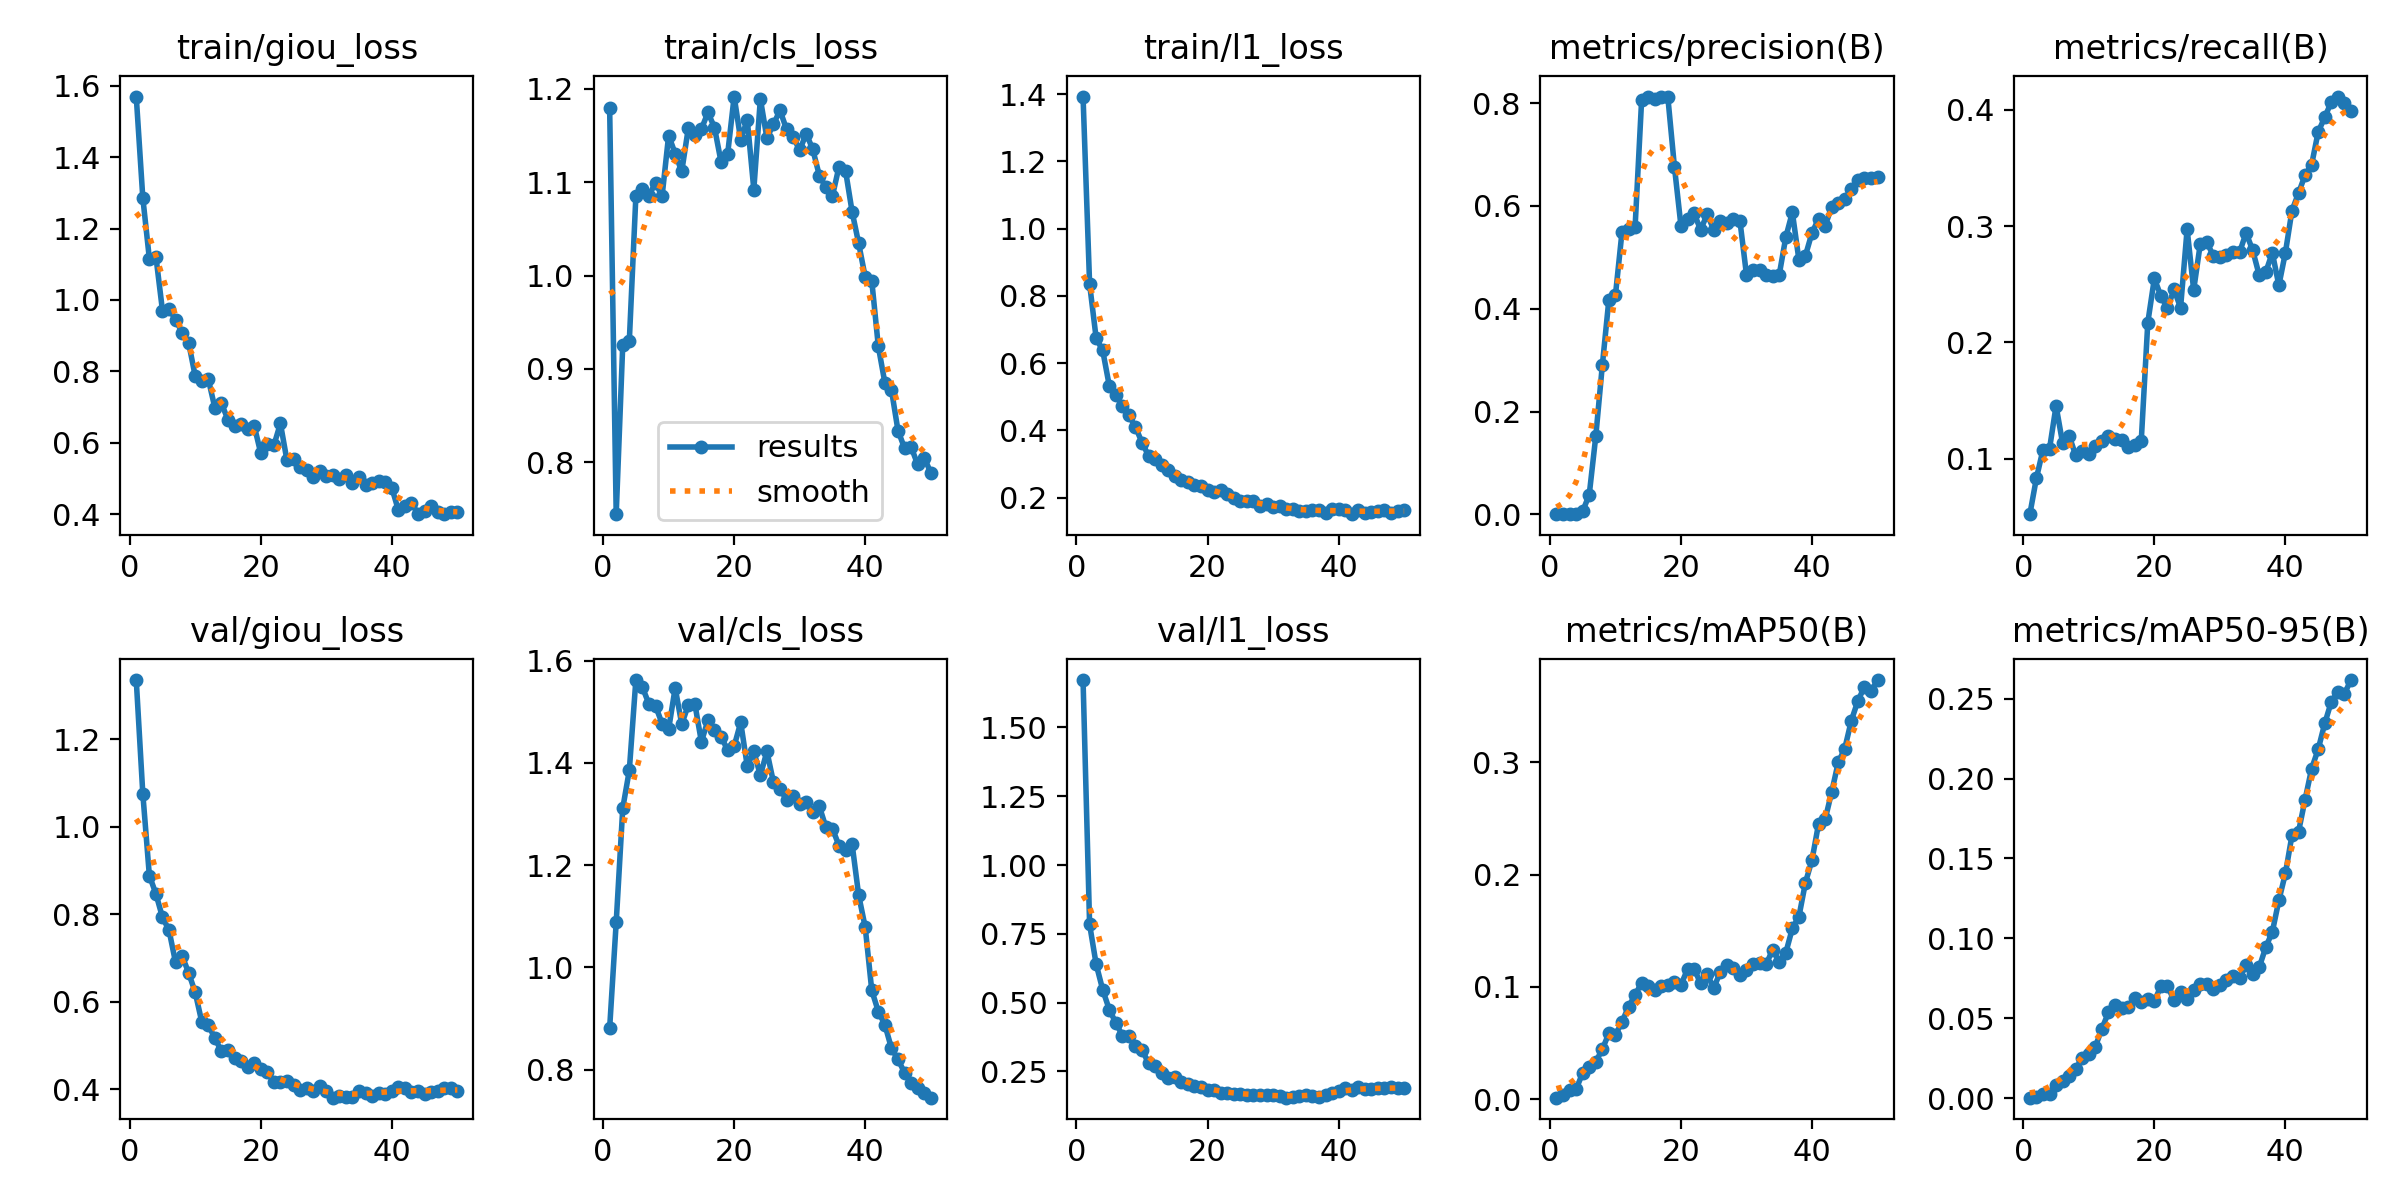

Showing: confusion_matrix.png


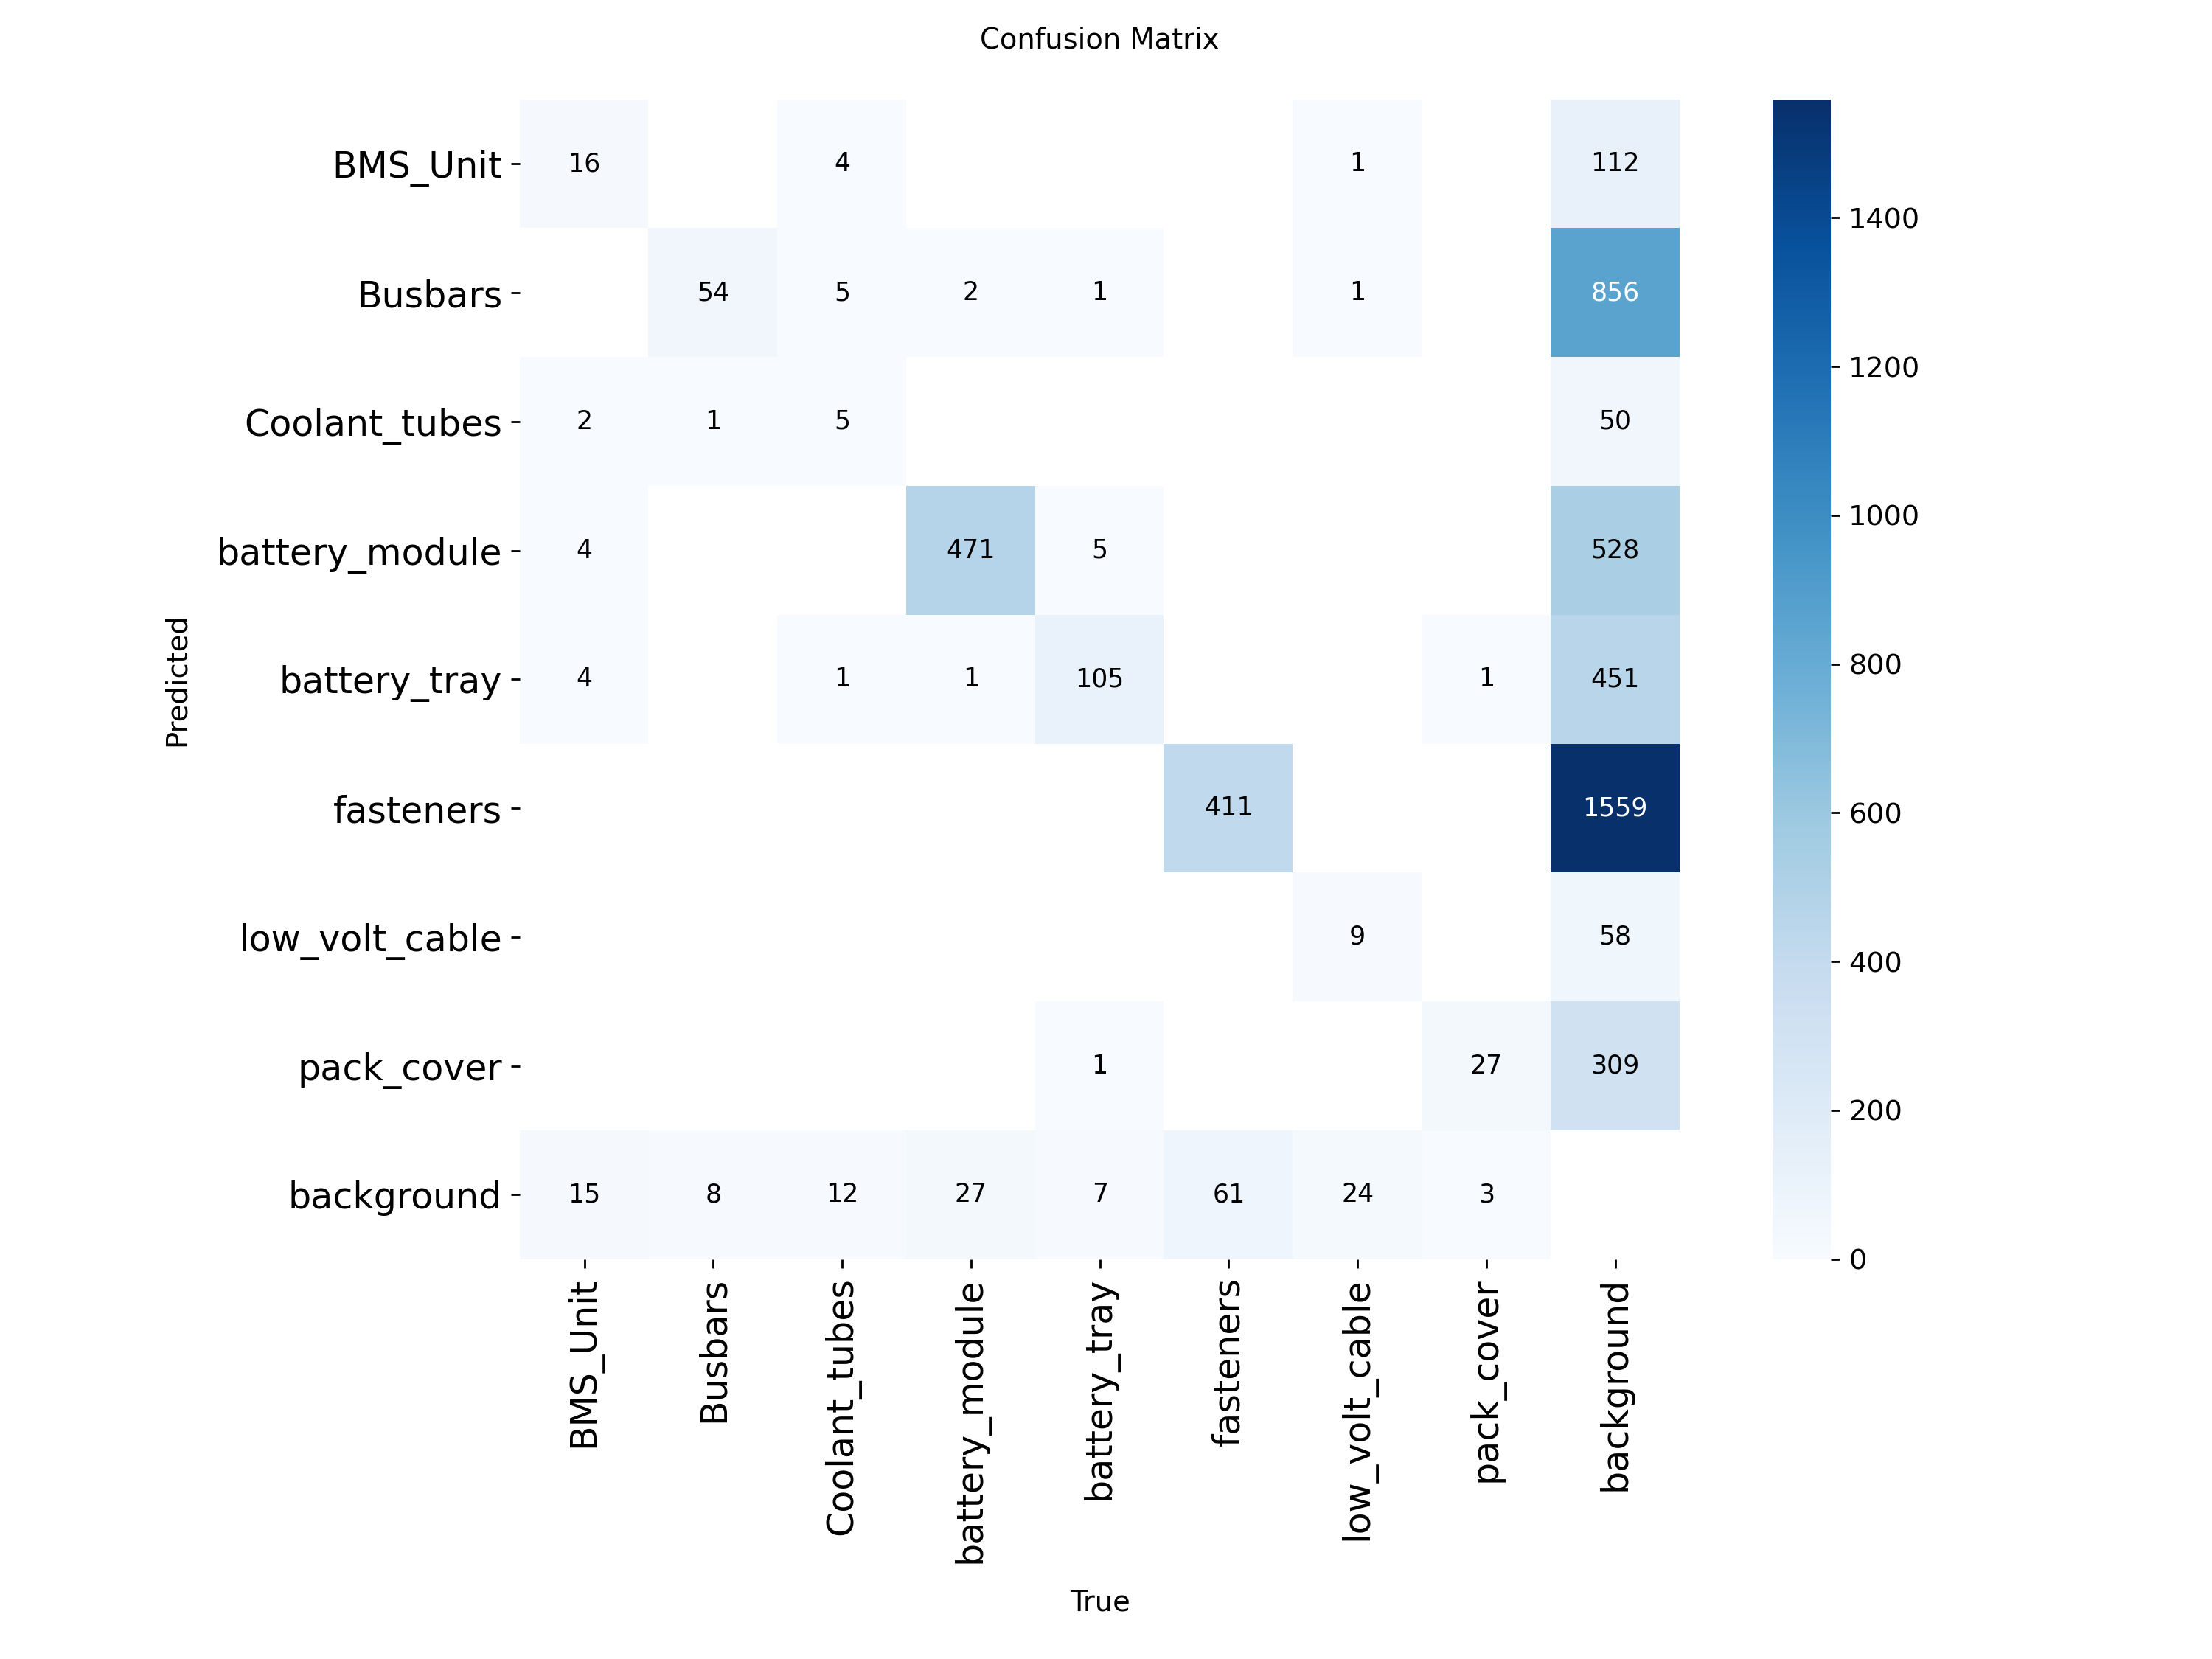

Showing: confusion_matrix_normalized.png


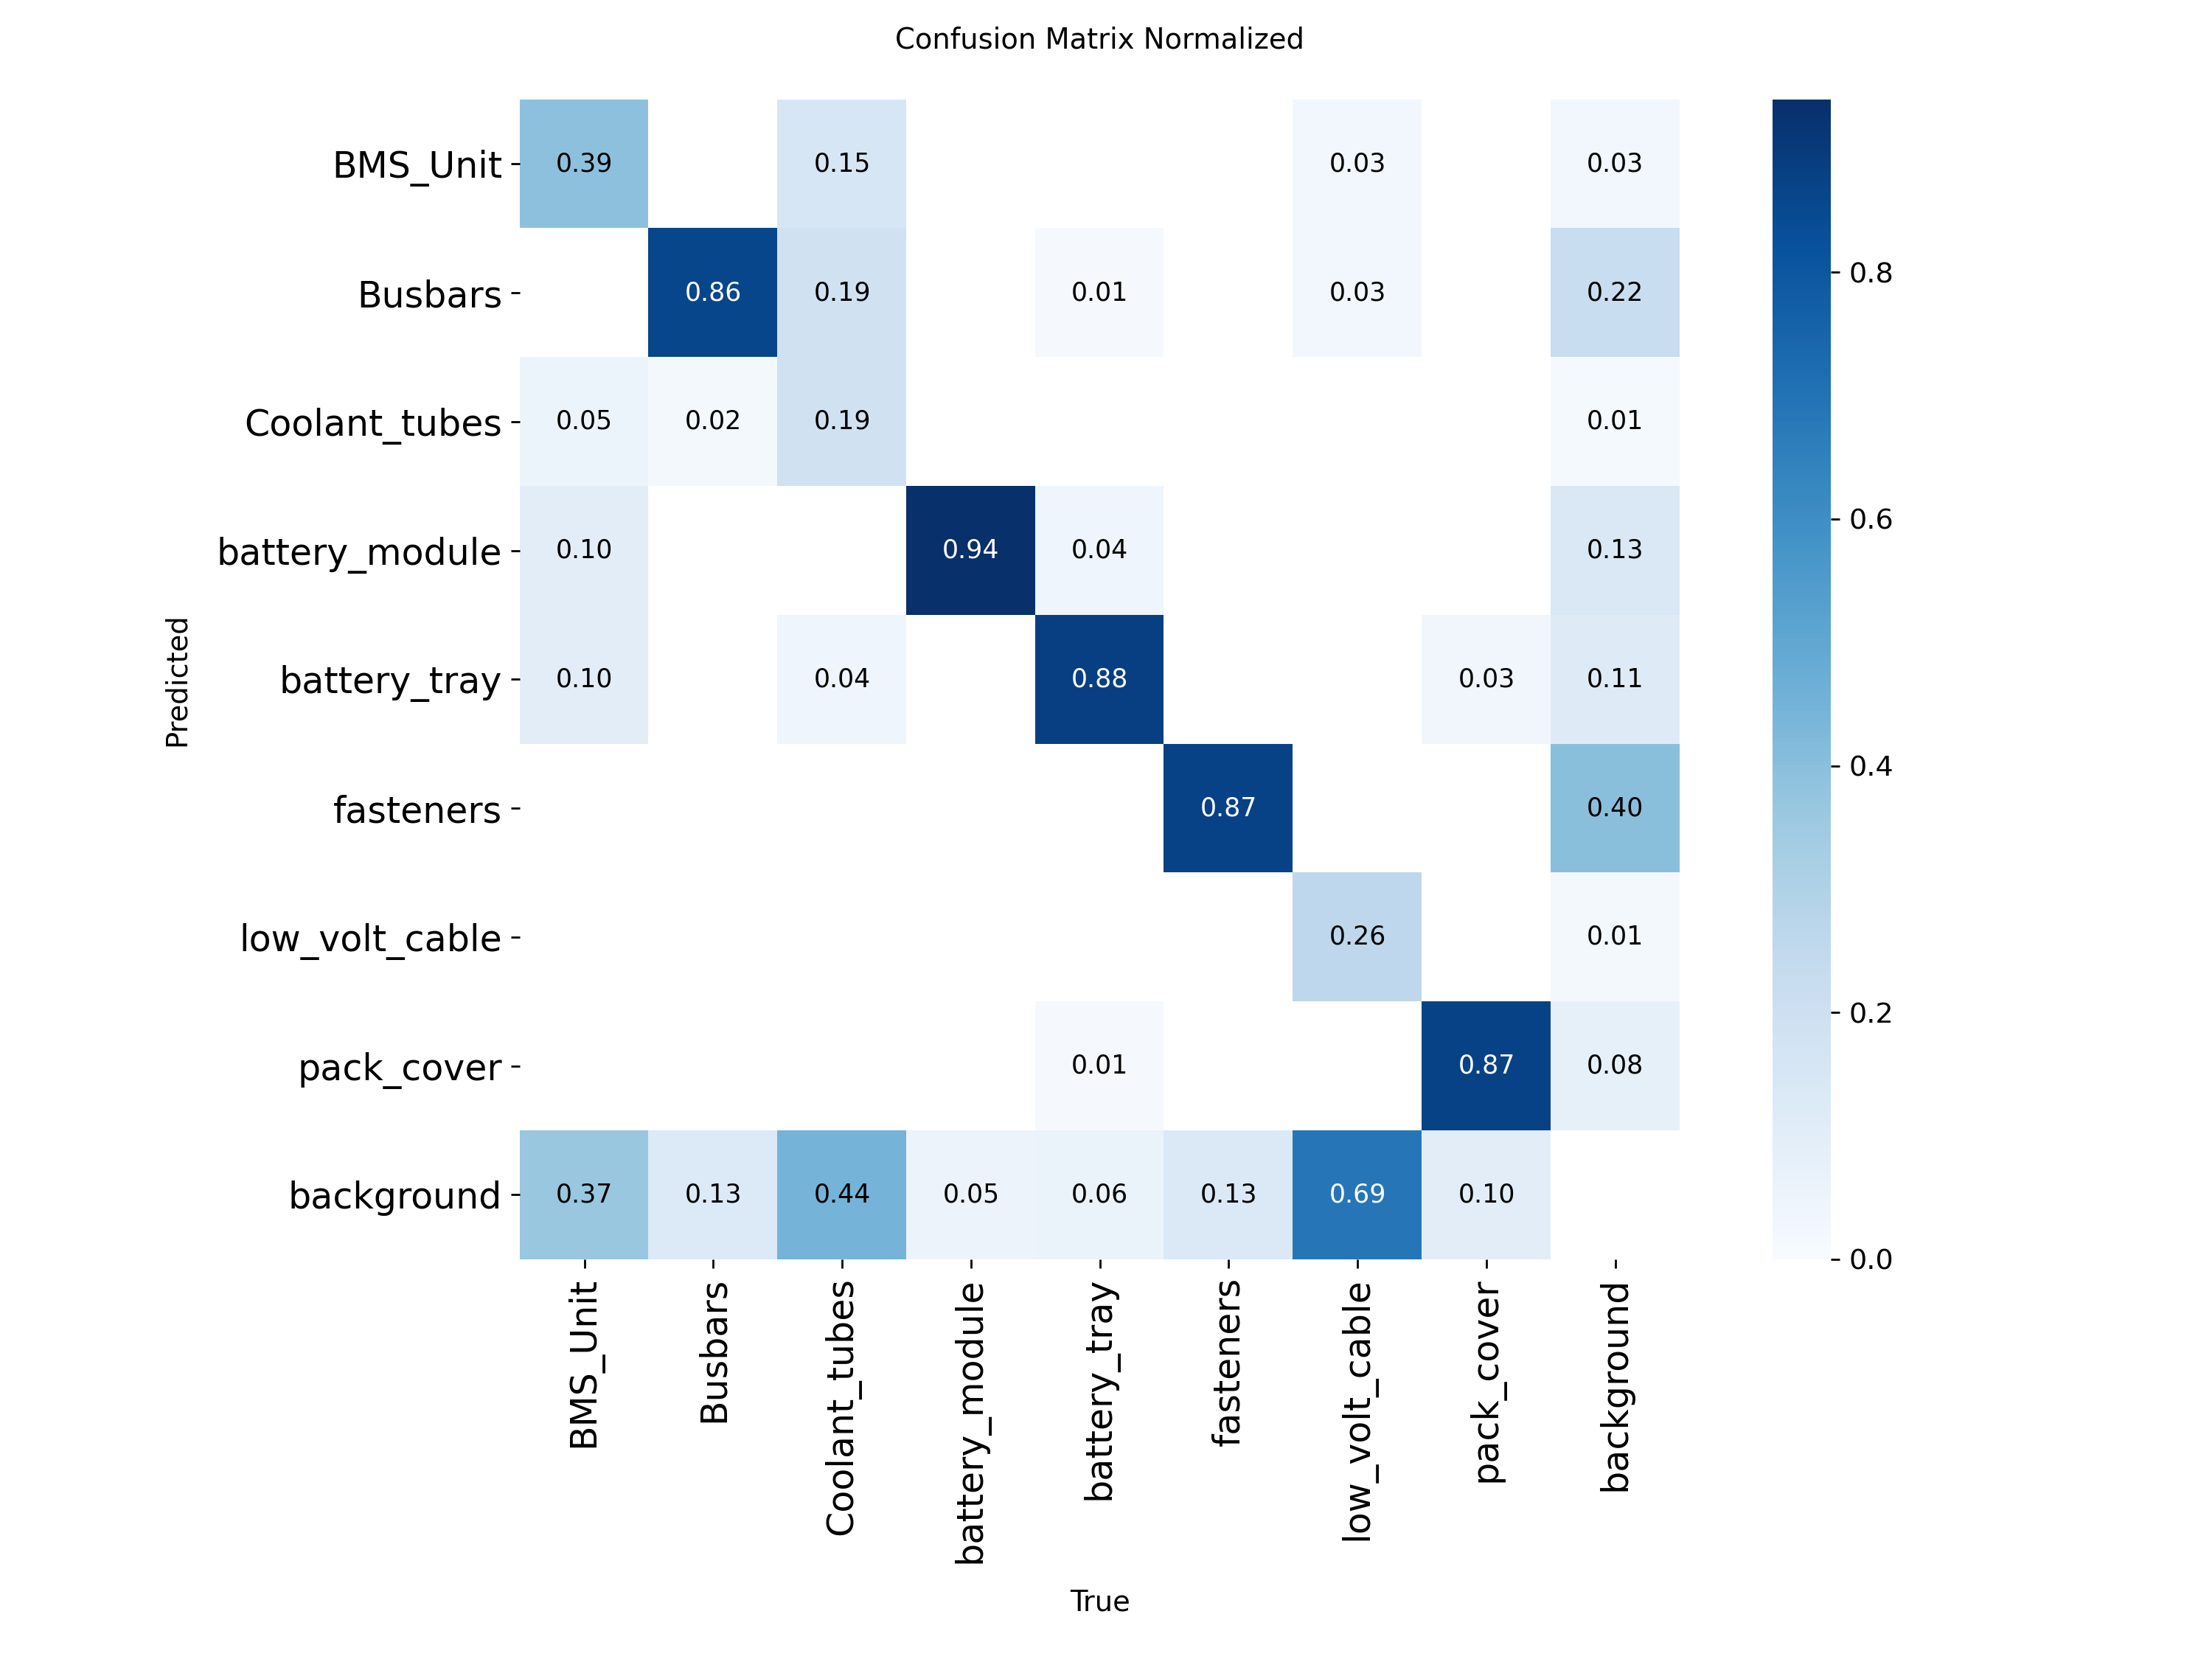

Showing: BoxPR_curve.png


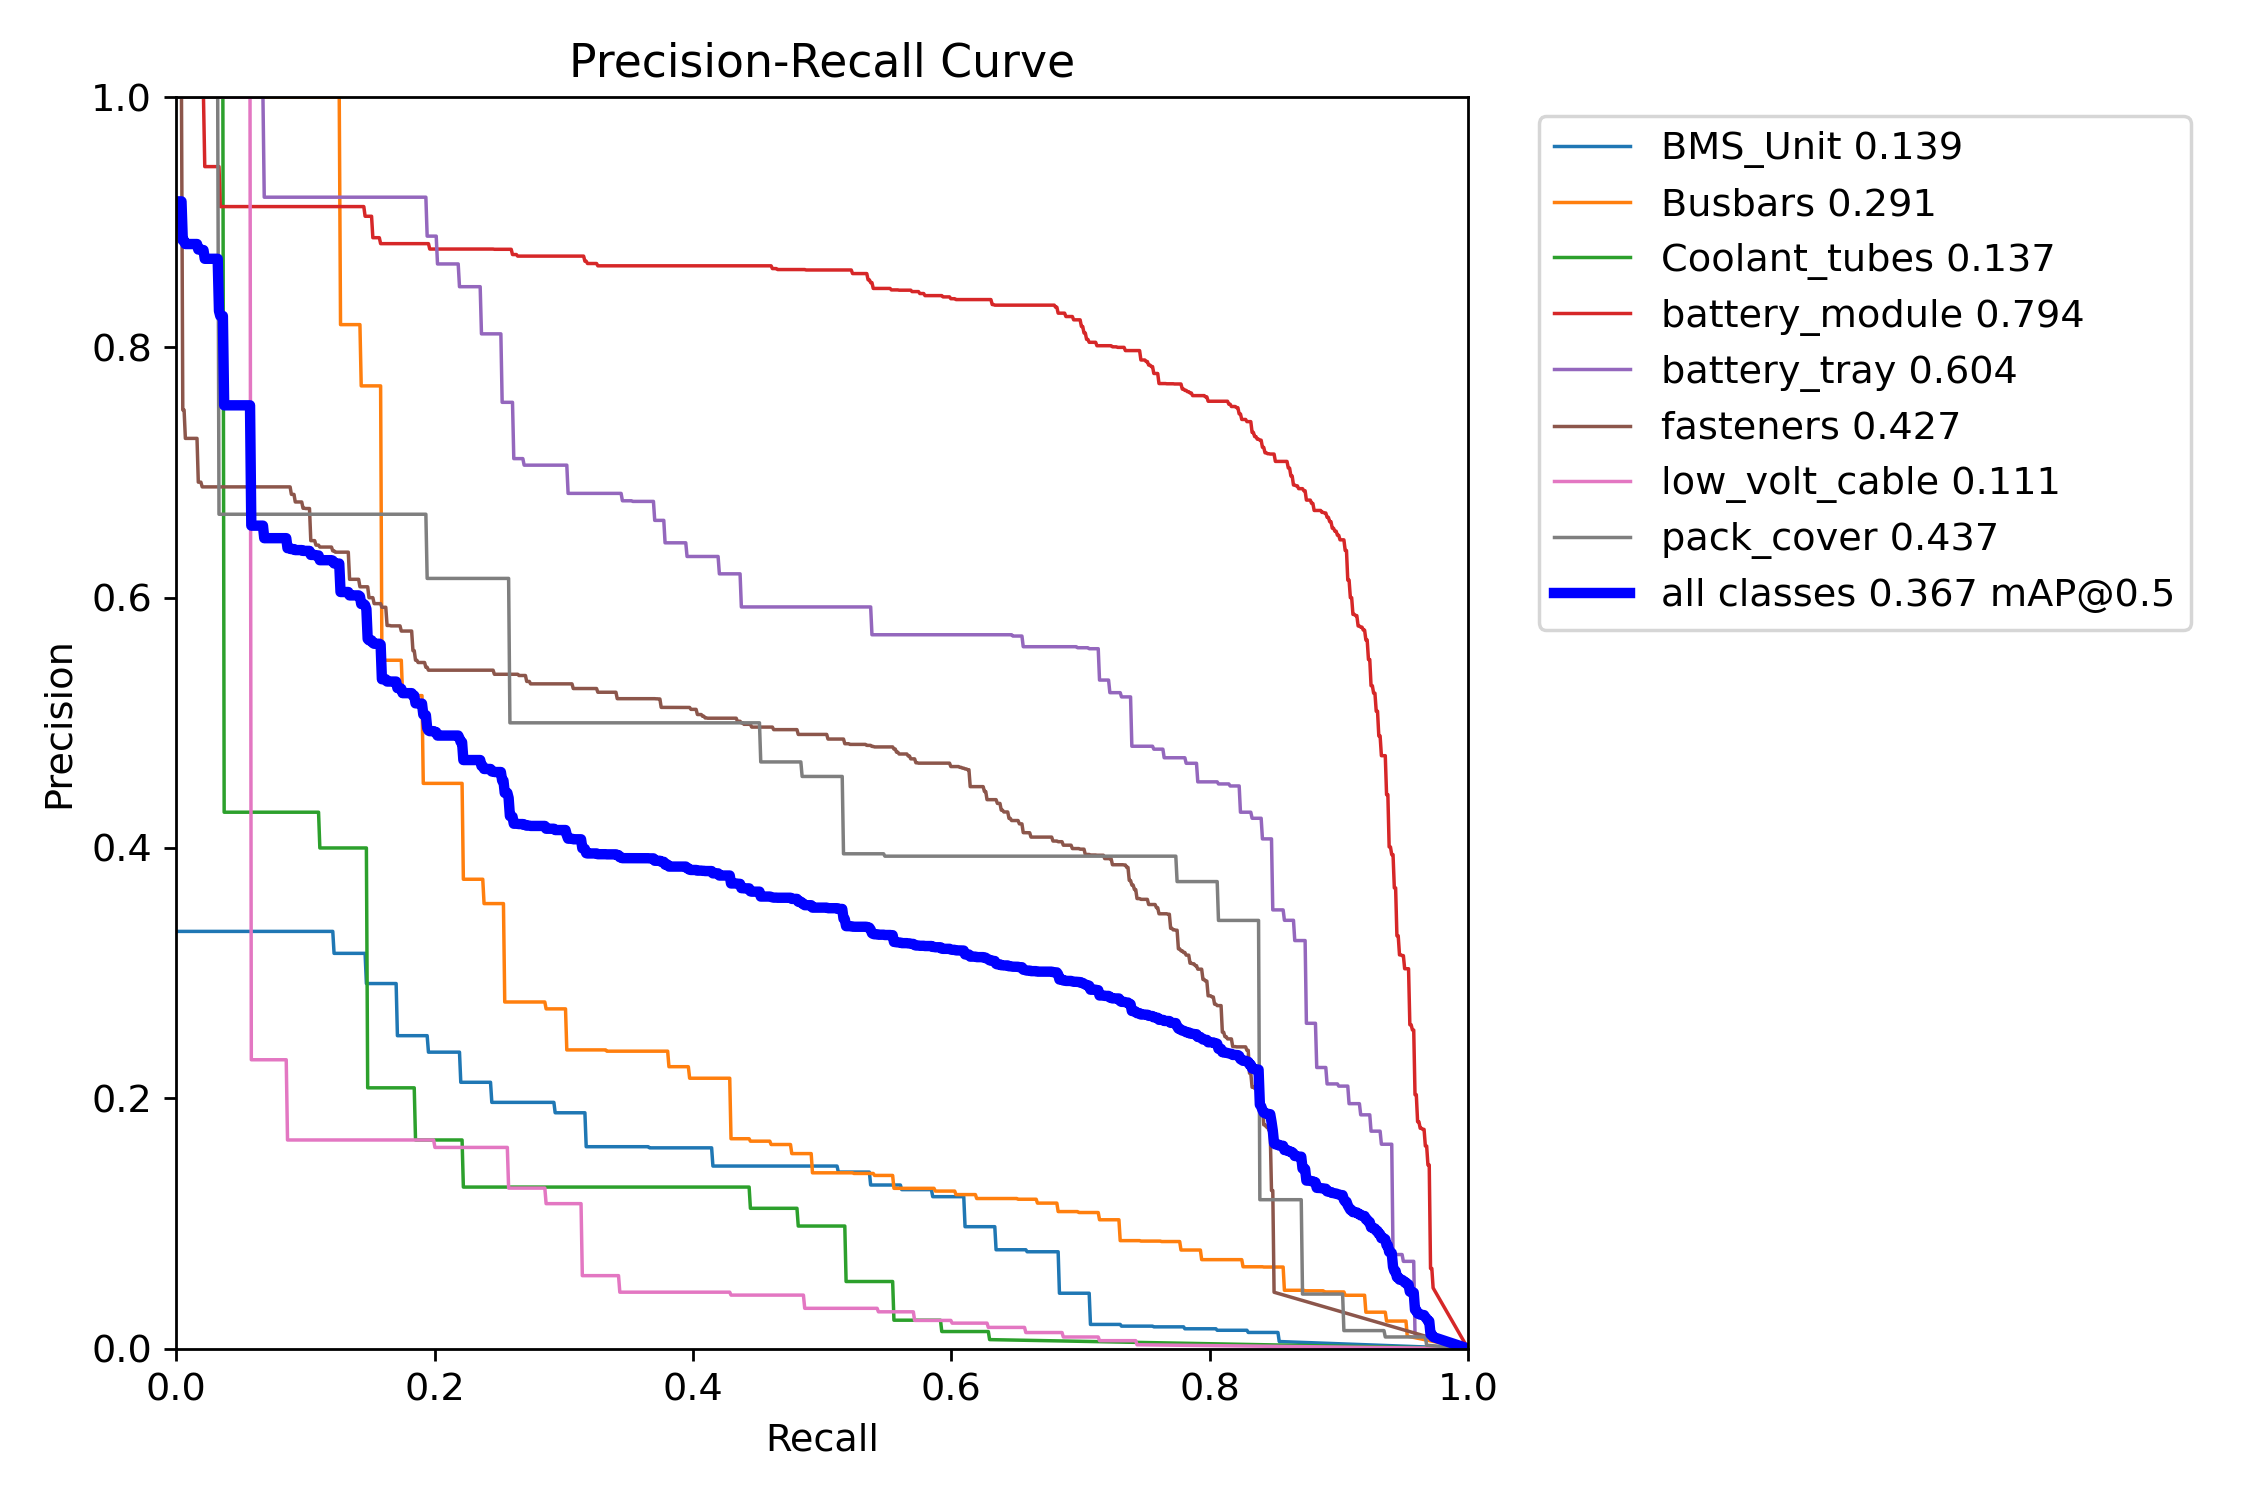

Showing: BoxF1_curve.png


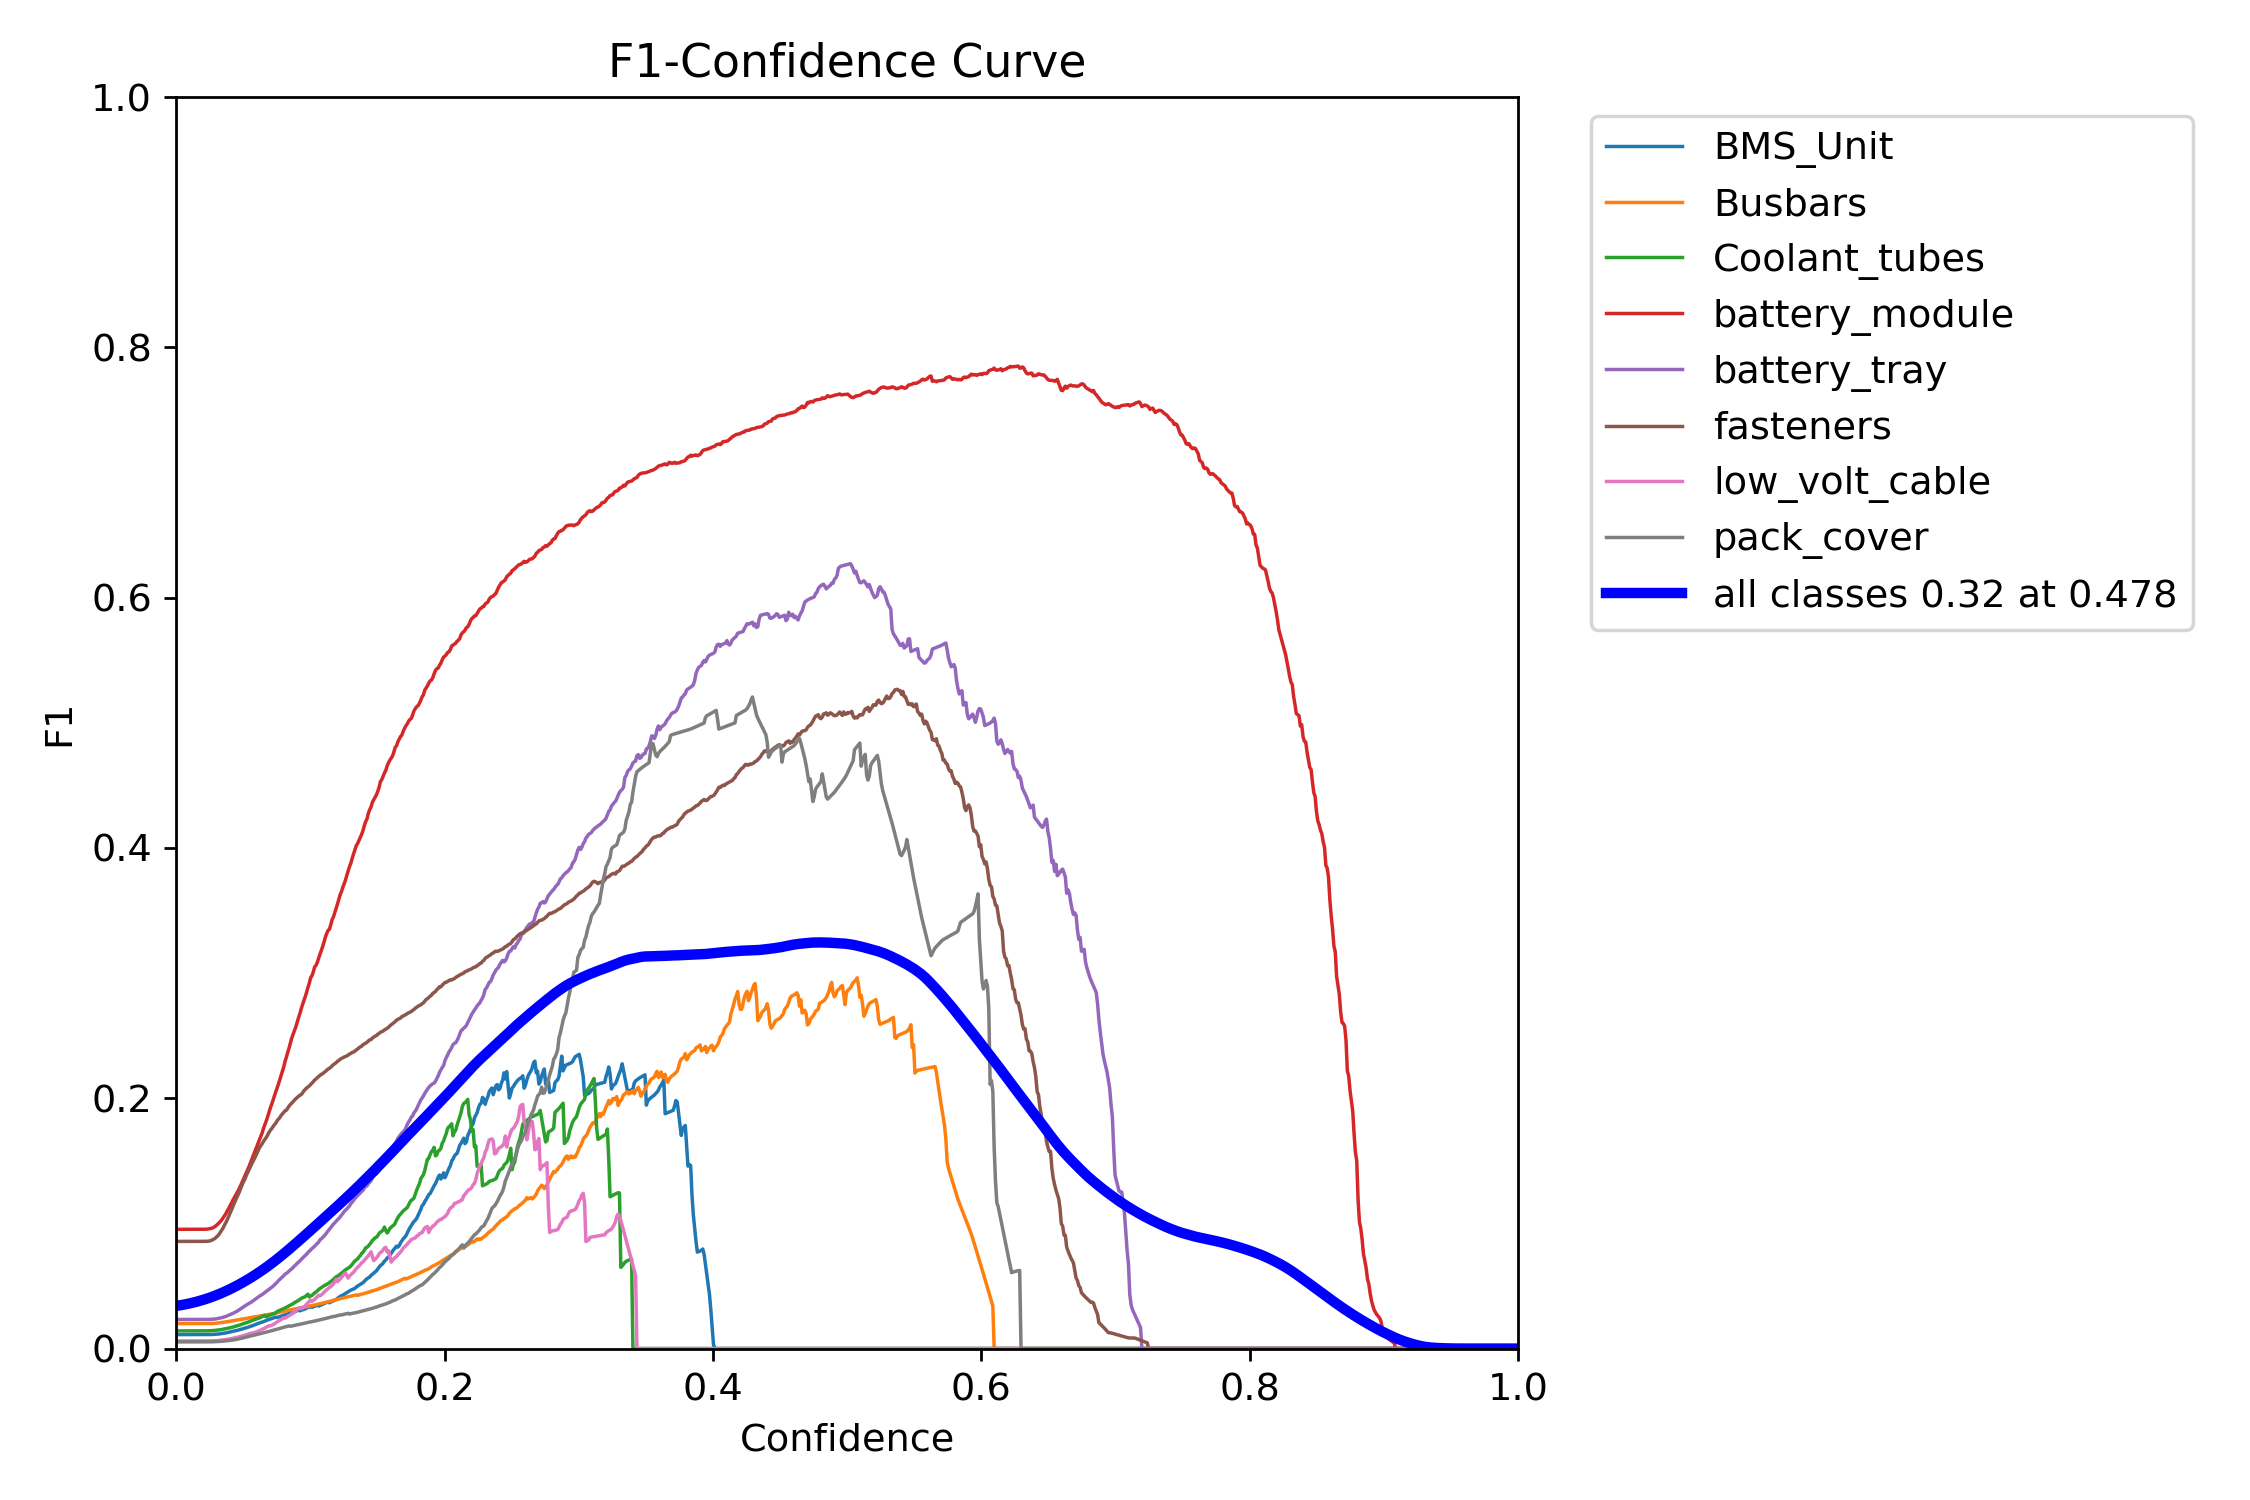

Showing: BoxP_curve.png


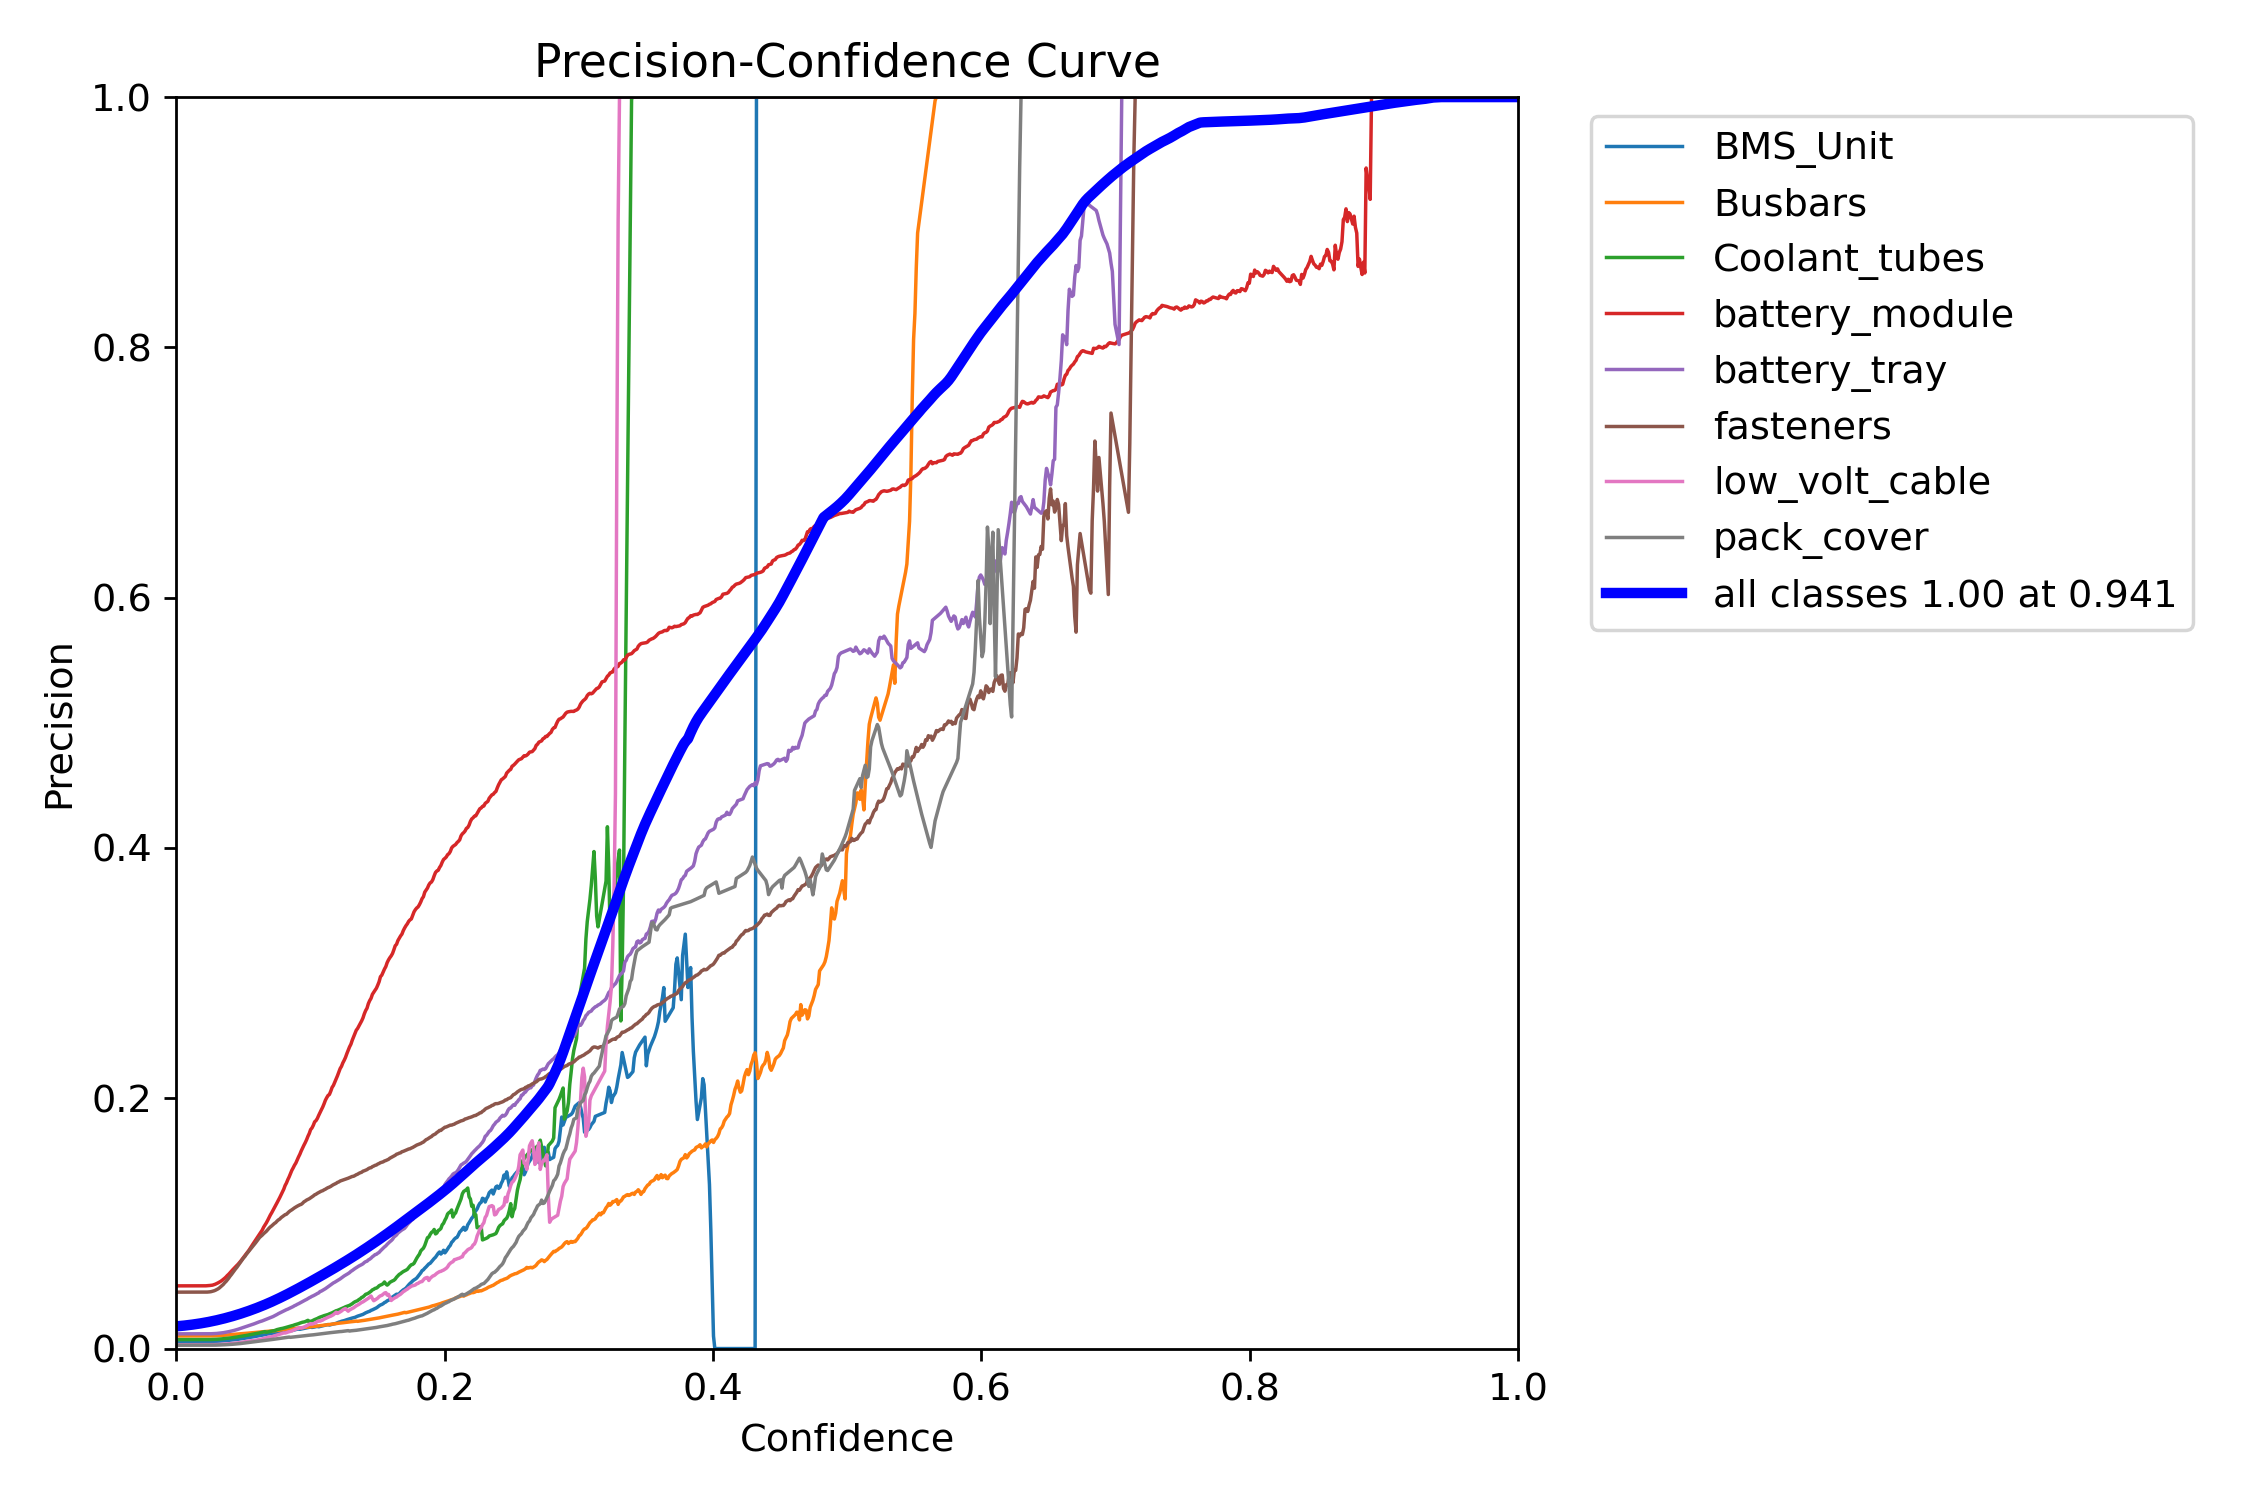

Showing: BoxR_curve.png


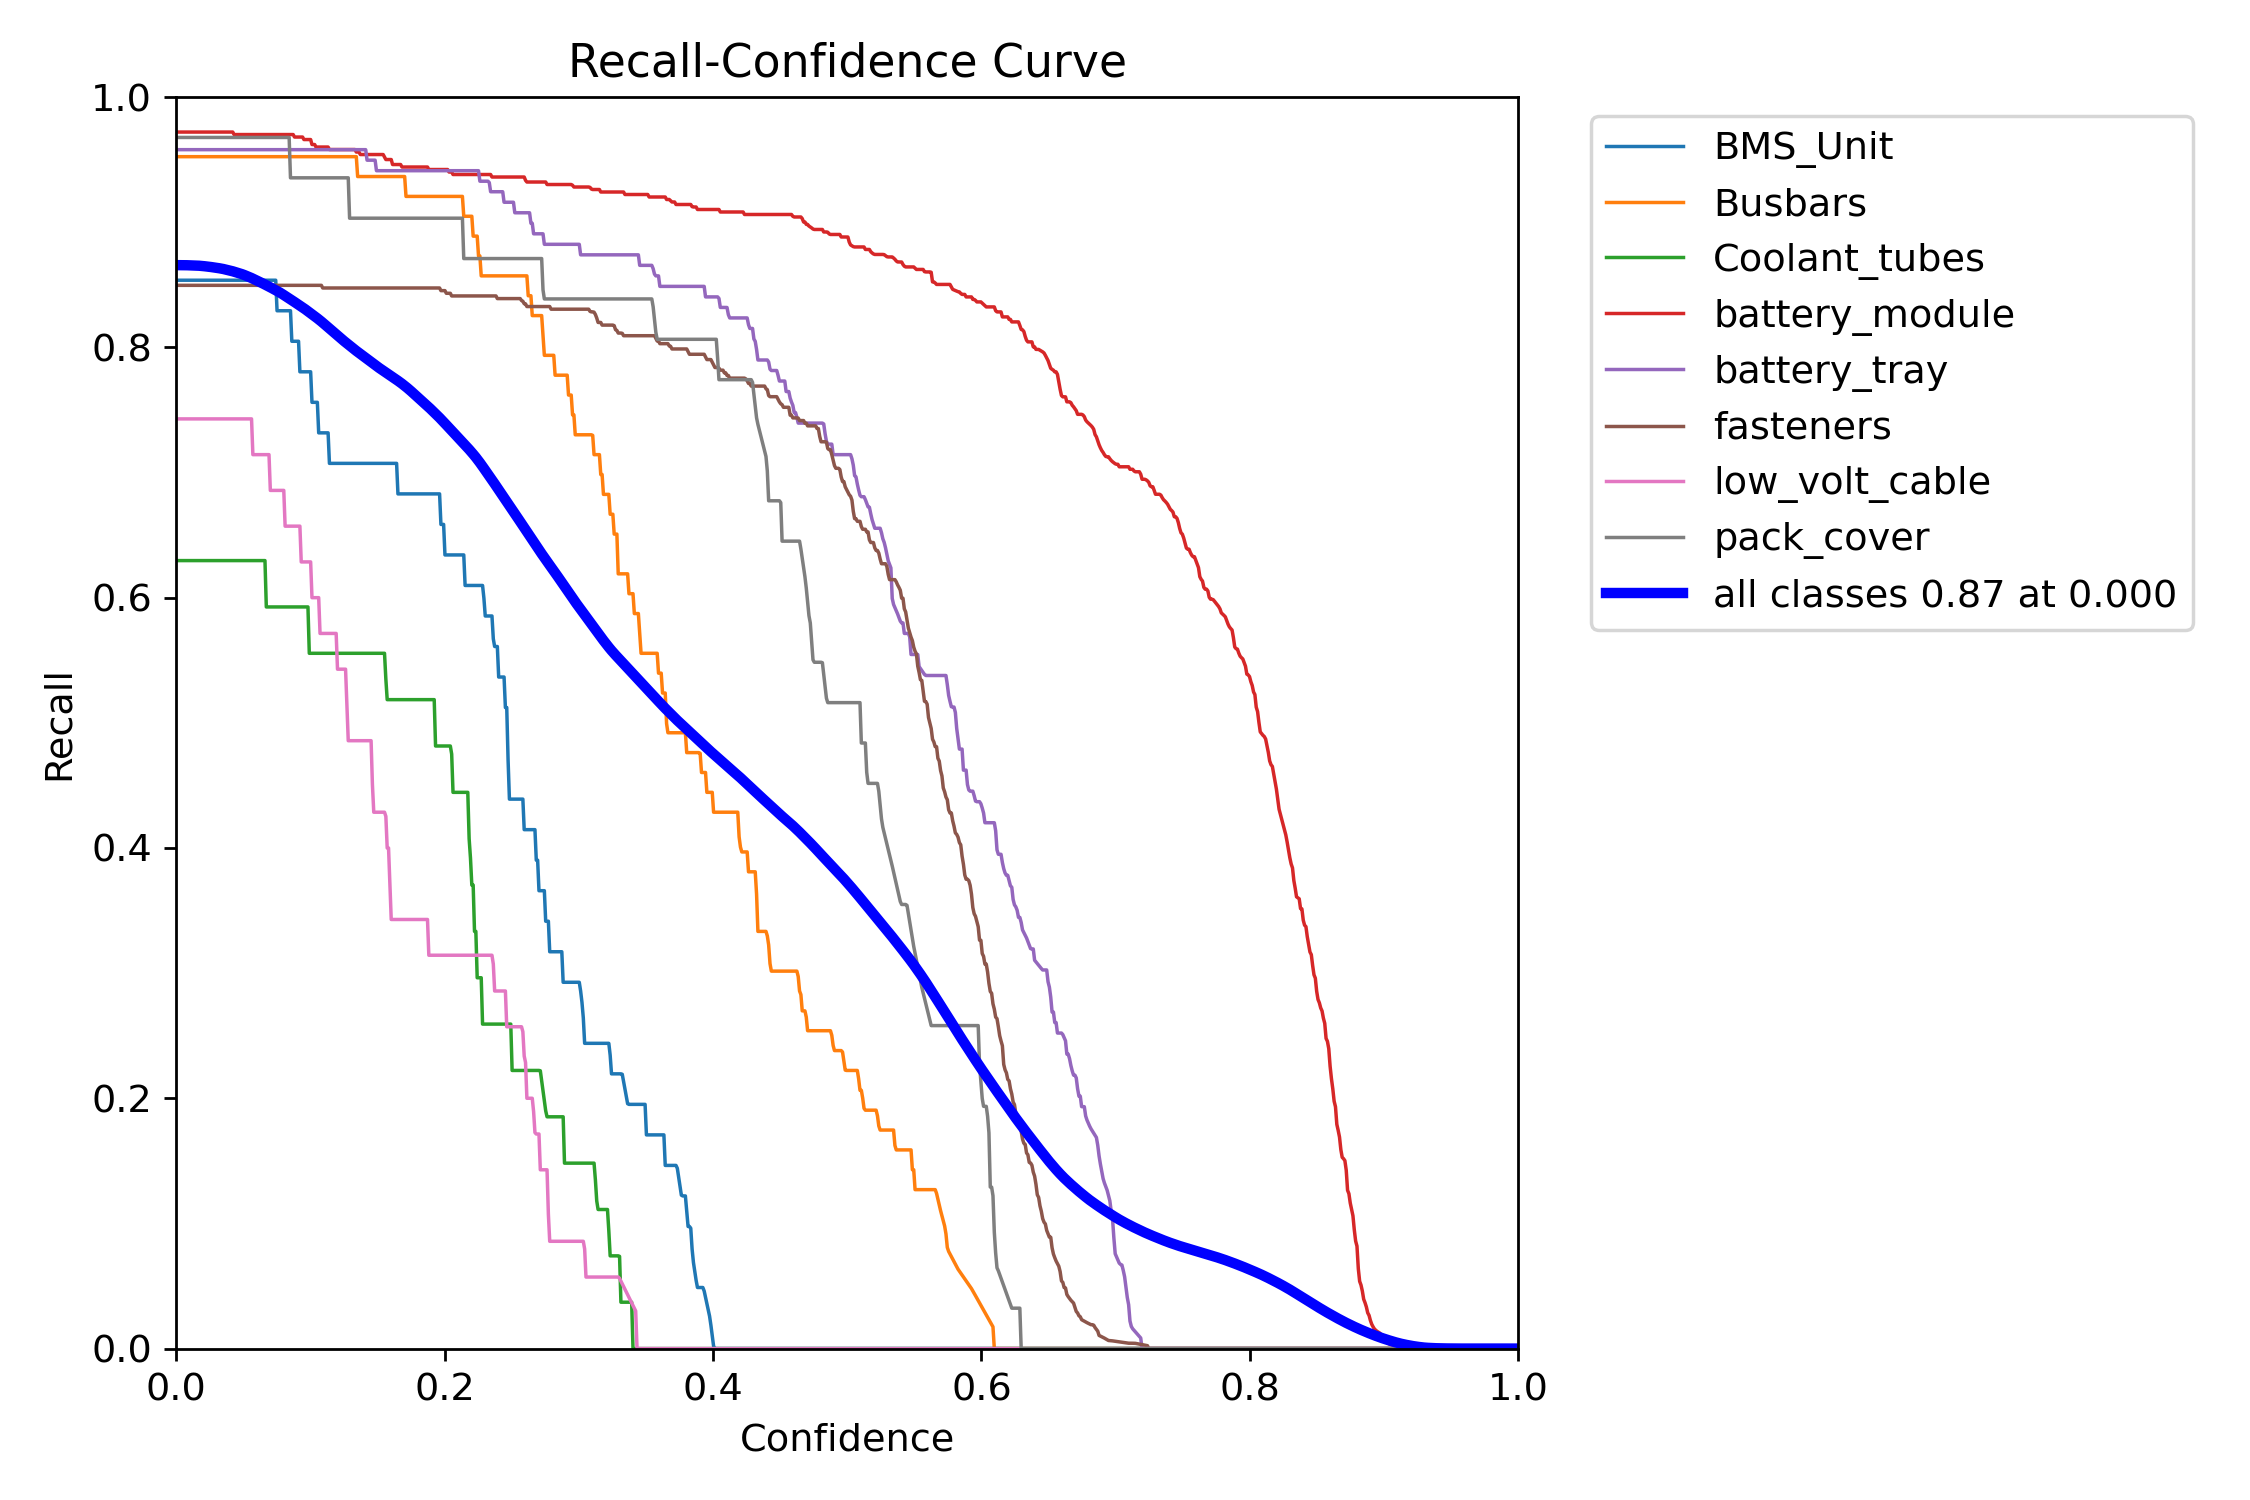

In [7]:
# VISUALISATIONS
from IPython.display import Image, display

run_dir = os.path.join(PROJECT_DIR, run_name)

def show_run_plots(run_dir, title):
    print(f"\n {title}")
    plot_files = [
        "results.png",
        "confusion_matrix.png",
        "confusion_matrix_normalized.png",
        "BoxPR_curve.png",
        "BoxF1_curve.png",
        "BoxP_curve.png",
        "BoxR_curve.png",
    ]
    for f in plot_files:
        p = os.path.join(run_dir, f)
        if os.path.exists(p):
            print(f"Showing: {f}")
            display(Image(filename=p))
        else:
            print(f"Missing: {f}")

show_run_plots(run_dir, "RT-DETR (Ultralytics)")